In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv("data.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [13]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          4
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [5]:
df.drop(["company","agent"],axis=1,inplace=True)

In [12]:
s=df["country"].value_counts(ascending=False).index[0]
df["country"].fillna(s,inplace=True)

In [15]:
k=[]
for i in df.columns:
    if df[i].dtype==object:
        k.append(i)

In [20]:
import scipy.stats as ss


In [33]:
for i in range(1,len(k)):
    o=pd.crosstab(df[k[i]],df["hotel"])
    
    statistic,pvalue,dof,expected_freq = ss.chi2_contingency(o,df["hotel"])
    print(k[i],"   ",statistic,"    ",pvalue)

arrival_date_month     598.130622992931      3.5175313992493777e-121
meal     11973.642827418096      0.0
country     11001.35099328865      0.0
market_segment     2576.4051525289024      0.0
distribution_channel     4177.883263377213      0.0
reserved_room_type     12434.648523735685      0.0
assigned_room_type     18269.138365830462      0.0
deposit_type     3721.9806894762955      0.0
customer_type     320.9033823518966      2.9729677552520673e-69
reservation_status     2226.1254607021565      0.0
reservation_status_date     10796.087264538162      0.0


In [ ]:
df["lead_time"].value_counts()

In [ ]:
#which customer type are mostly booked

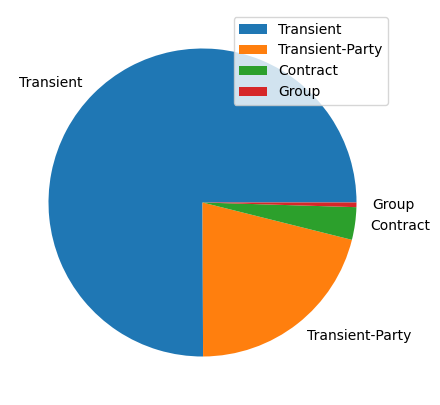

In [222]:
ct=df["customer_type"].value_counts()
plt.figure(figsize=(5,5))
plt.pie(ct,labels=ct.index)
plt.legend(loc="upper right")
plt.show()
#transient are most booked

In [ ]:
df["is_canceled"].value_counts()

In [ ]:
df["arrival_date_year"].value_counts()

In [ ]:
s=df.groupby("arrival_date_year")["is_canceled"].value_counts()
values=s.values
f=values[::2]
g=values[1::2]
s

In [ ]:
g

In [ ]:
year=[2015,2016,2017]
a=[0,1]
plt.bar(year,f,width=0.4)
plt.bar(year,g,width=0.4,bottom=f)
for i in year:
    plt.text(i,f)
    

In [ ]:
df.columns

In [ ]:
#Which type Hotel have highest booking

In [223]:
y=df['hotel'].value_counts()
x=df["hotel"].value_counts().index

C:\Users\megha\AppData\Local\Temp\ipykernel_14260\1397919758.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(x[i],y[i]+1000,y[i])


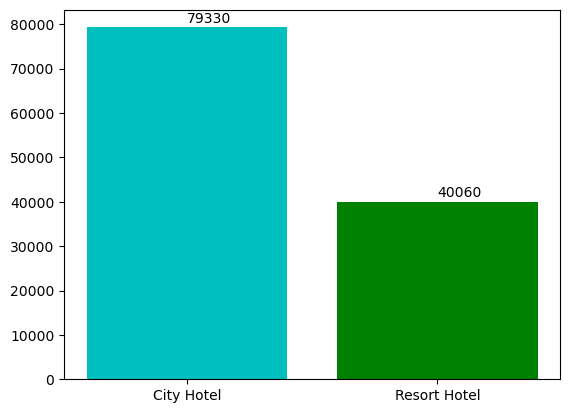

In [224]:
plt.bar(x,y,color=["c","g"])
for i in range(len(x)):
    plt.text(x[i],y[i]+1000,y[i])
plt.show()
#City Hotel are mostly booked as comapre to resort hotel

In [ ]:
# Year Wise Booking Trends

In [4]:
city=df[df["hotel"]=="City Hotel"]['arrival_date_year'].value_counts()


In [5]:
Resort=df[df["hotel"]=="Resort Hotel"]['arrival_date_year'].value_counts()


In [6]:
x=Resort.index


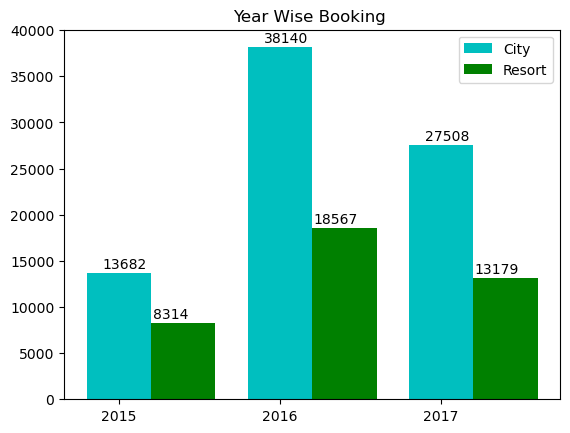

In [229]:
w=0.4
plt.bar(x,city,width=w,label="City",color="c")
plt.bar(x+w,Resort,width=w,label="Resort",color="g")
plt.legend()
plt.title("Year Wise Booking ")
plt.xticks(x)
for i in range(len(x)):
    plt.text(x[i]-0.1,city.values[i]+500,city.values[i])
    plt.text(x[i]+0.21,Resort.values[i]+500,Resort.values[i])
plt.show()

#in 2016 there are most booked 

In [3]:
df["month_num"]=pd.to_datetime(df['arrival_date_month'], format='%B').dt.month

In [230]:
#Which month was most booked hotels 

In [320]:
city=list(df[df["hotel"]=="City Hotel"]["month_num"].value_counts().sort_index().values)


In [321]:
Resort=list(df[df["hotel"]=="Resort Hotel"]["month_num"].value_counts().sort_index().values)
x=np.sort(df["month_num"].unique())

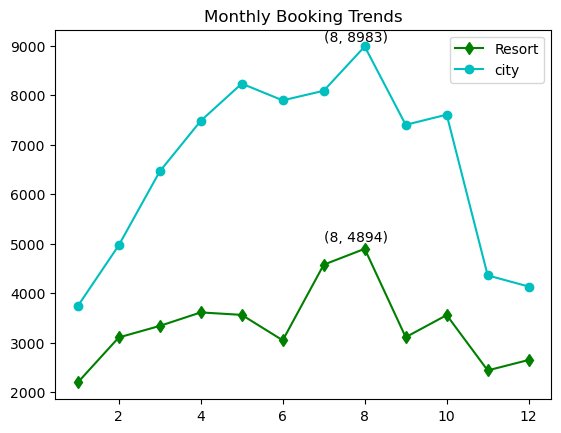

In [324]:
#Which month was most booked hotels 

plt.plot(x,Resort,color="g",marker="d",label="Resort")
plt.plot(x,city,color="c",marker="o",label="city")
plt.legend()
plt.title("Monthly Booking Trends")
plt.text(city.index(max(city)),max(city)+100,(city.index(max(city))+1,int(max(city))))
plt.text(Resort.index(max(Resort)),max(Resort)+150,(Resort.index(max(Resort))+1,int(max(Resort))))
plt.show()

# In month August month the most hotel was booked

In [234]:
#year of  the Week booking Trends

In [10]:
city=list(df[df["hotel"]=="City Hotel"]["arrival_date_week_number"].value_counts().sort_index().values)

In [11]:
Resort=list(df[df["hotel"]=="Resort Hotel"]["arrival_date_week_number"].value_counts().sort_index().values)
x=np.sort(df["arrival_date_week_number"].unique())

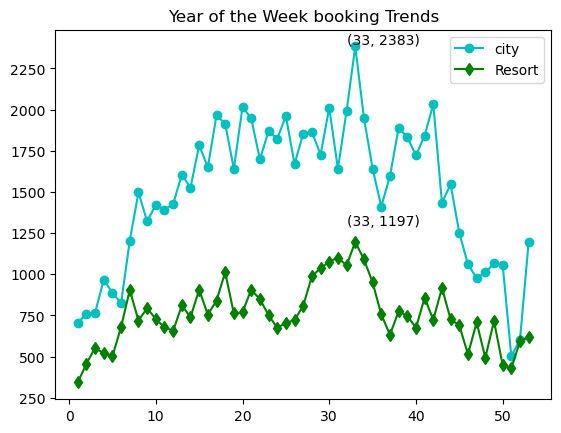

In [12]:
plt.plot(x,city,label="city",marker='o',color="c")
plt.plot(x,Resort,label="Resort",marker="d",color="g")
plt.legend()
plt.title("Year of the Week booking Trends")
plt.text(city.index(max(city)),max(city)+10,(city.index(max(city))+1,int(max(city))))
plt.text(Resort.index(max(Resort)),max(Resort)+100,(Resort.index(max(Resort))+1,int(max(Resort))))   
plt.show()
#In Week 32 the most hotel was booked

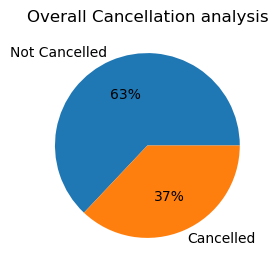

In [28]:
#overall Cancellation analysis 
cancel=df["is_canceled"].value_counts()
plt.figure(figsize=(3,3))
plt.pie(cancel,labels=["Not Cancelled","Cancelled"],autopct="%.f%%")

plt.title("Overall Cancellation analysis")
plt.show()

# there are 37% of booking cancelled

In [17]:
#which type of hotels are most cancelled

In [4]:
Resort_cancel=df[df["hotel"]=="Resort Hotel"]["is_canceled"].value_counts()
city_cancel=df[df["hotel"]=="City Hotel"]["is_canceled"].value_counts()
l=["Not cancelled","Cancelled"]
w=0.4

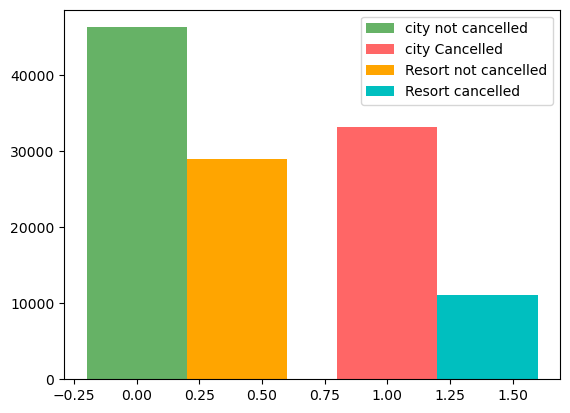

In [8]:
x=np.array([0,1])
plt.bar(x,city_cancel,color=["g","r"],alpha=0.6,width=w,label=["city not cancelled","city Cancelled"])
plt.bar(x+w,Resort_cancel,width=w,label=["Resort not cancelled","Resort cancelled"],color=["orange","c"])
#plt.xticks(["Not Canceled ","Canceled"])
plt.legend()
plt.show()

In [47]:
Resort_cancel

is_canceled
0    28938
1    11122
Name: count, dtype: int64

In [48]:
city_cancel

is_canceled
0    46228
1    33102
Name: count, dtype: int64

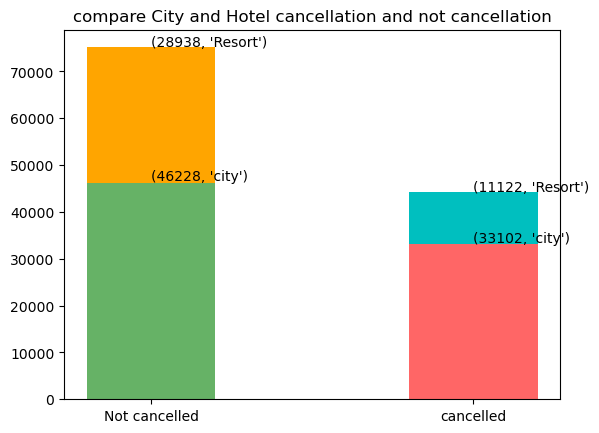

In [94]:
plt.bar(x,city_cancel,color=["g","r"],alpha=0.6,width=0.4,label=["city Hotel not cancelled","city Hotel Cancelled"])
plt.bar(x,Resort_cancel,bottom=city_cancel,width=0.4,label=["Resort Hotel not cancelled","Resort Hotel cancelled"],color=["orange","c"])
plt.xticks(ticks=[0,1],labels=["Not cancelled","cancelled"])
#plt.legend()
plt.title("compare City and Hotel cancellation and not cancellation")
for i in range(len(x)):
    plt.text(x[i],city_cancel[i]+500,(int(city_cancel[i]),"city"))
    plt.text(x[i],Resort_cancel[i]+city_cancel[i]+200,(int(Resort_cancel[i]),"Resort"))
plt.show()

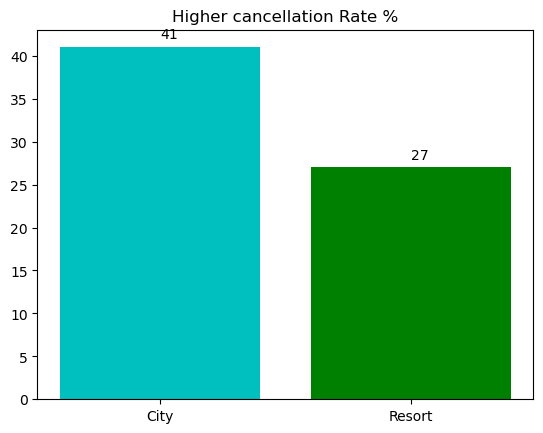

In [130]:
#Which hotel has a higher cancellation problem?
Resort_cancel=df[df["hotel"]=="Resort Hotel"]["is_canceled"]
city_cancel=df[df["hotel"]=="City Hotel"]["is_canceled"]
cancel=[int(city_cancel.sum()/city_cancel.value_counts().sum()*100),int(Resort_cancel.sum()/Resort_cancel.value_counts().sum()*100)]
x=["City","Resort"]
plt.bar(x,cancel,color=["c","g"])
plt.title("Higher cancellation Rate %")
plt.text(x[0],cancel[0]+1,cancel[0])
plt.text(x[1],cancel[1]+1,cancel[1])
plt.show()

In [113]:
Resort_cancel.value_counts()

is_canceled
0    28938
1    11122
Name: count, dtype: int64

In [5]:
#Month-wise Cancellation Rate
city=df[df["hotel"]=="City Hotel"]
city_cancel=city[city["is_canceled"]==1]["month_num"].value_counts().sort_index().values
city_total_booking=city[city["is_canceled"]==0]["month_num"].value_counts().sort_index().values+city_cancel
city_cancel_rate=city_cancel/city_total_booking*100

Resort=df[df["hotel"]=="Resort Hotel"]
Resort_cancel=Resort[Resort["is_canceled"]==1]["month_num"].value_counts().sort_index().values
Resort_total_booking=Resort[Resort["is_canceled"]==0]["month_num"].value_counts().sort_index().values+city_cancel
Resort_cancel_rate=Resort_cancel/Resort_total_booking*100

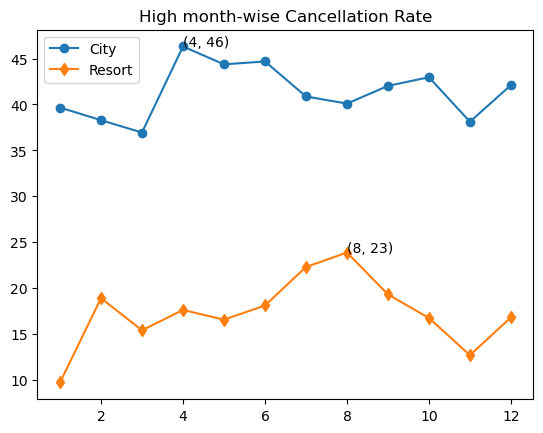

In [6]:
x=np.arange(1,13)
plt.plot(x,city_cancel_rate,marker="o",label="City")
plt.plot(x,Resort_cancel_rate,marker="d",label="Resort")
plt.legend()
plt.title("High month-wise Cancellation Rate")
plt.text(np.argmax(city_cancel_rate)+1,city_cancel_rate[np.argmax(city_cancel_rate)],(int(np.argmax(city_cancel_rate))+1,int(city_cancel_rate[np.argmax(city_cancel_rate)])))
plt.text(np.argmax(Resort_cancel_rate)+1,Resort_cancel_rate[np.argmax(Resort_cancel_rate)],(int(np.argmax(Resort_cancel_rate))+1,int(Resort_cancel_rate[np.argmax(Resort_cancel_rate)])))
plt.show()

In [9]:
#Lead Time vs Cancellation


In [286]:
s=df.groupby("lead_time")["is_canceled"].value_counts().sort_index().reset_index()
s[s["is_canceled"]==1]["count"].sum()

np.int64(44224)

In [ ]:
city=df[df["hotel"]=="City Hotel"]
city[city["is_canceled"]==1]

In [86]:
s=df.groupby("hotel")[["is_canceled","lead_time"]].value_counts().sort_index().reset_index()
d=s[s["hotel"]=="City Hotel"]
f=d[d["is_canceled"]==1][["lead_time","count"]].sort_values("lead_time")
x=f["lead_time"]
y=f["count"].values
g=d[d["is_canceled"]==0][["lead_time","count"]].sort_values("lead_time")

In [ ]:
plt.hist(y)

# Customers kis segment se aa rahe hain?

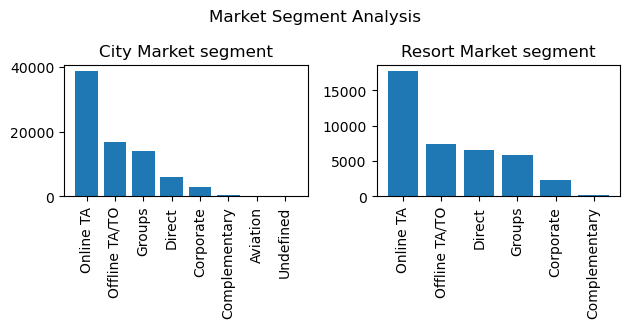

In [310]:
#Market Segment Analysis
plt.subplot(2,2,1)
City=df[df["hotel"]=="City Hotel"]["market_segment"].value_counts()
plt.title("City Market segment")
plt.bar(City.index,City.values)
plt.xticks(rotation = 90)
plt.subplot(2,2,2)
Resort=df[df["hotel"]=="Resort Hotel"]["market_segment"].value_counts()
plt.title("Resort Market segment")
plt.bar(Resort.index,Resort.values)
plt.xticks(rotation = 90)
plt.suptitle("Market Segment Analysis")
plt.tight_layout()

In [102]:
#Market Segment vs Cancellation

In [201]:
#City Market segment Cancelation Rate

In [295]:
market=df[df["hotel"]=="City Hotel"]
d=market.groupby("market_segment")["is_canceled"].value_counts().reset_index()
city_cancel=d[d["is_canceled"]==1].sort_values("market_segment",ascending=True)["count"].values
city_not_cancel=d[d["is_canceled"]==0].sort_values("market_segment",ascending=True)["count"].values
market_city_cancel=city_cancel[:-1]/(city_cancel[:-1]+city_not_cancel)*100
y=d[d["is_canceled"]==1].sort_values("market_segment",ascending=True)["market_segment"].values


In [297]:
#Resort market Segmemt Cancelation rate
market_Resort=df[df["hotel"]=="Resort Hotel"]
d=market_Resort.groupby("market_segment")["is_canceled"].value_counts().reset_index()
Resort_cancel=d[d["is_canceled"]==1].sort_values("market_segment",ascending=True)["count"].values
Resort_not_cancel=d[d["is_canceled"]==0].sort_values("market_segment",ascending=True)["count"].values
market_Resort_cancel=Resort_cancel/(Resort_cancel+Resort_not_cancel)*100
x=d[d["is_canceled"]==1].sort_values("market_segment",ascending=True)["market_segment"].values

# Question: Kaunsa market segment cancellation ke liye high-risk hai?

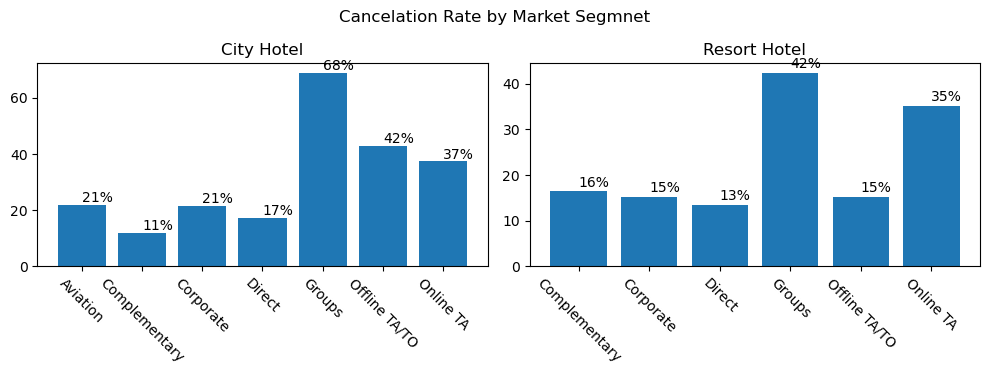

In [308]:
##Market Segment vs Cancellation

plt.figure(figsize=(10,6))
plt.subplot(2,2,1)
plt.bar(y[:-1],market_city_cancel)
plt.xticks(rotation=-45)
plt.title("City Hotel")
for i in range(len(y[:-1])):
    plt.text(y[i],market_city_cancel[i]+1,f"{int(market_city_cancel[i])}%")
plt.subplot(2,2,2)
plt.bar(x,market_Resort_cancel)
plt.xticks(rotation=-45)
plt.title("Resort Hotel")
for i in range(len(x)):
    plt.text(x[i],market_Resort_cancel[i]+1,f"{int(market_Resort_cancel[i])}%")
plt.suptitle("Cancelation Rate by Market Segmnet")
plt.tight_layout()

In [ ]:
#ADR Analysis


# Question: Hotel rooms average monthly price changes ?

In [361]:
city=df[df["hotel"]=="City Hotel"]
s=city.groupby("month_num")["adr"].mean().sort_index()

Resort=df[df["hotel"]=="Resort Hotel"]
d=Resort.groupby("month_num")["adr"].mean().sort_index()

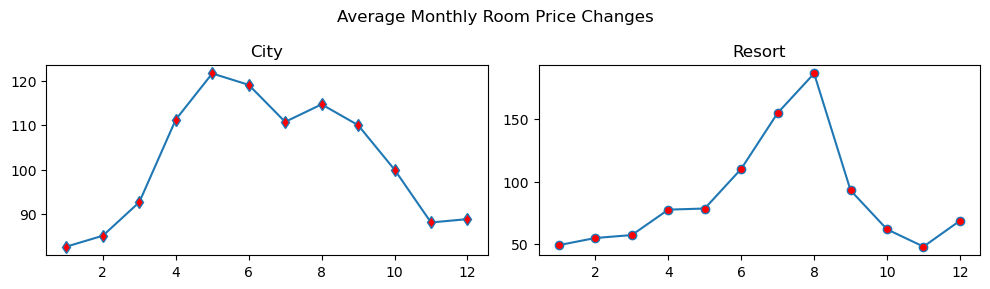

In [365]:
plt.figure(figsize=(10,5))
plt.subplot(2,2,1)
plt.plot(s.index,s,marker="d",mfc="r")
plt.title("City")
plt.subplot(2,2,2)
plt.plot(d.index,d,marker="o",mfc="r")
plt.title("Resort")
plt.suptitle("Average Monthly Room Price Changes")
plt.tight_layout()

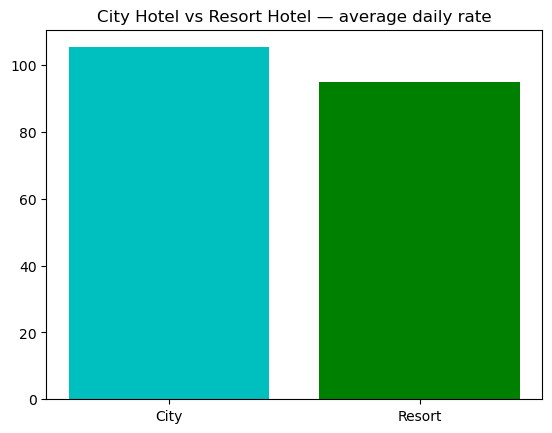

In [374]:
R=Resort["adr"].mean()
C=city["adr"].mean()
x=["City","Resort"]
y=[C,R]
plt.title("City Hotel vs Resort Hotel — average daily rate")
plt.bar(x,y,color=["c","g"])
plt.show()

In [ ]:
df.columns

# Deposit Type vs Cancellation

In [138]:
#city Hotel

city=df[df["hotel"]=="City Hotel"]
d=city.groupby("deposit_type")['is_canceled'].value_counts().reset_index()
deposit_cancel=d[d["is_canceled"]==1].sort_index()
deposite_not_cancel=d[d["is_canceled"]==0].sort_index()
x=deposit_cancel["deposit_type"].values
y=deposit_cancel["count"].values/(deposit_cancel["count"].values+deposite_not_cancel["count"].values)*100

In [141]:
# Resort Hotel

Resort=df[df["hotel"]=="Resort Hotel"]
Resort_d=Resort.groupby("deposit_type")['is_canceled'].value_counts().reset_index()
Resort_deposit_cancel=Resort_d[Resort_d["is_canceled"]==1].sort_index()
Resort_deposite_not_cancel=Resort_d[Resort_d["is_canceled"]==0].sort_index()
Resort_dx=Resort_deposit_cancel["deposit_type"].values
Resort_dy=Resort_deposit_cancel["count"].values/(Resort_deposit_cancel["count"].values+Resort_deposite_not_cancel["count"].values)*100

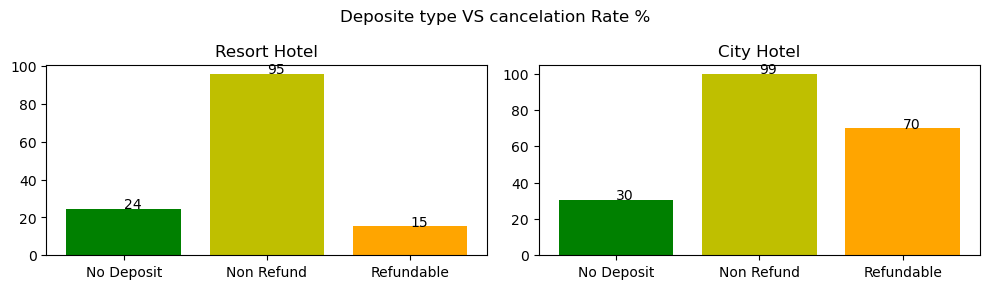

In [153]:
plt.figure(figsize=(10,5))
plt.subplot(2,2,1)
plt.bar(Resort_dx,Resort_dy,color=["g","y","orange"])
plt.title("Resort Hotel"  )
for i in range(len(Resort_dx)):
    plt.text(Resort_dx[i],Resort_dy[i],int(Resort_dy[i]))
plt.subplot(2,2,2)
plt.bar(x,y,color=["g","y","orange"])
plt.title("City Hotel"  )
for i in range(len(x)):
    plt.text(x[i],y[i],int(y[i]))
plt.suptitle("Deposite type VS cancelation Rate %")
plt.tight_layout()

# which customer type are mostly booked

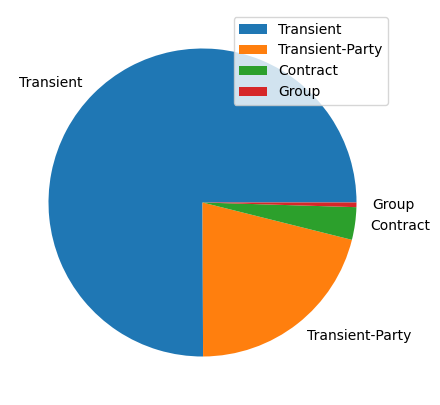

In [288]:
ct=df["customer_type"].value_counts()
plt.figure(figsize=(5,5))
plt.pie(ct,labels=ct.index)
plt.legend(loc="upper right")
plt.show()
#transient are most booked

# customer type cancelation rate

In [116]:
city=df[df["hotel"]=="City Hotel"]
Resort=df[df["hotel"]=="Resort Hotel"]

In [126]:
#city Hotel 

d=city.groupby("customer_type")["is_canceled"].value_counts().reset_index()
city_customer_type_cancel=d[d["is_canceled"]==1].sort_index()
city_customer_type_not_cancel=d[d["is_canceled"]==0].sort_index()
city_x=city_customer_type_cancel["customer_type"].values
city_y=city_customer_type_cancel["count"].values/(city_customer_type_not_cancel["count"].values+city_customer_type_cancel["count"].values)*100

In [127]:
#Resort Hotel

Resort_d=Resort.groupby("customer_type")["is_canceled"].value_counts().reset_index()
Resort_customer_type_cancel=Resort_d[Resort_d["is_canceled"]==1].sort_index()
Resort_customer_type_not_cancel=Resort_d[Resort_d["is_canceled"]==0].sort_index()
Resort_x=Resort_customer_type_cancel["customer_type"].values
Resort_y=Resort_customer_type_cancel["count"].values/(Resort_customer_type_not_cancel["count"].values+Resort_customer_type_cancel["count"].values)*100

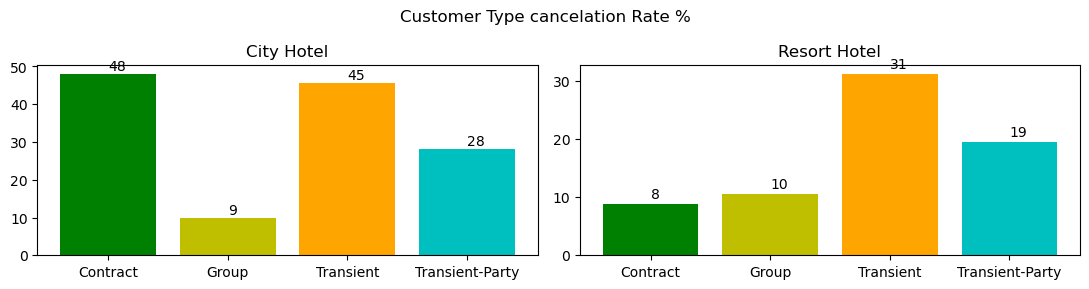

In [137]:
plt.figure(figsize=(11,5))
plt.subplot(2,2,1)
plt.bar(city_x,city_y,color=["g","y",'orange',"c"])
plt.title("City Hotel")
for i in range(len(city_x)):
    plt.text(city_x[i],city_y[i]+1,int(city_y[i]))
plt.subplot(2,2,2)
plt.bar(Resort_x,Resort_y,color=["g","y",'orange',"c"])
plt.title("Resort Hotel")
for i in range(len(Resort_x)):
    plt.text(Resort_x[i],Resort_y[i]+1,int(Resort_y[i]))
plt.suptitle("Customer Type cancelation Rate %")
plt.tight_layout()

# Top 10 Countries booking

In [196]:
country=df.groupby("hotel")["country"].value_counts().reset_index()

In [199]:
#city country

city_country=country[country["hotel"]=="City Hotel"].nlargest(10,"count")[["country","count"]]
city_country_x=city_country["country"].values
city_country_y=city_country["count"].values

In [200]:
#Resort country

Resort_country=country[country["hotel"]=="Resort Hotel"].nlargest(10,"count")[["country","count"]]
Resort_country_x=Resort_country["country"].values
Resort_country_y=Resort_country["count"].values

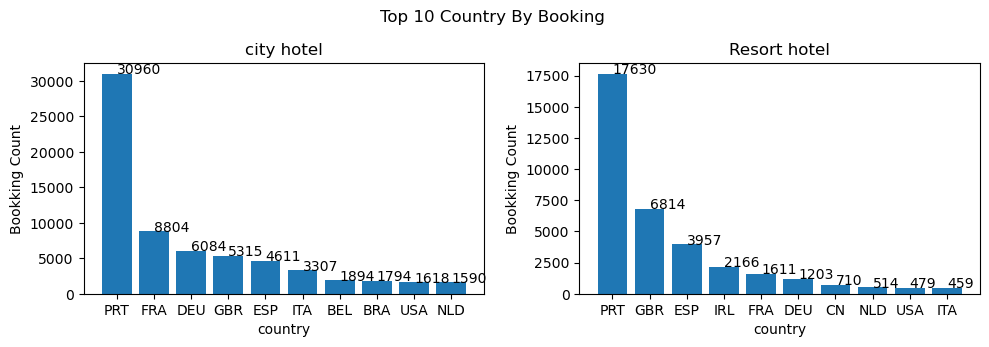

In [263]:
plt.figure(figsize=(10,6))
plt.subplot(2,2,1)
plt.bar(city_country_x,city_country_y)
plt.title("city hotel")
plt.xlabel("country")
plt.ylabel("Bookking Count")
for i in range(len(city_country_x)):
    plt.text(city_country_x[i],city_country_y[i],city_country_y[i])
plt.subplot(2,2,2)
plt.bar(Resort_country_x,Resort_country_y)
plt.title("Resort hotel")
plt.xlabel("country")
plt.ylabel("Bookking Count")
for i in range(len(Resort_country_x)):
    plt.text(Resort_country_x[i],Resort_country_y[i],Resort_country_y[i])
plt.suptitle("Top 10 Country By Booking ")

plt.tight_layout()

# top Country cancelation rate %

In [ ]:
cancel_country=df.groupby("hotel")["country"].value_counts().reset_index()

In [279]:
#city

g=city.groupby('country')["is_canceled"].value_counts().reset_index()
cancel=g[g["is_canceled"]==1].nlargest(10,"count").sort_values("country")
f=g[g['country'].isin(cancel["country"].values)]
not_cancel=f[f["is_canceled"]==0]["count"].values
x=cancel["country"].values
y=cancel["count"].values/(cancel["count"].values+not_cancel)*100

#Resort 

r_g=Resort.groupby('country')["is_canceled"].value_counts().reset_index()
r_cancel=r_g[r_g["is_canceled"]==1].nlargest(10,"count").sort_values("country")
r_f=r_g[r_g['country'].isin(r_cancel["country"].values)]
r_not_cancel=r_f[r_f["is_canceled"]==0]["count"].values
r_x=r_cancel["country"].values
r_y=r_cancel["count"].values/(r_cancel["count"].values+r_not_cancel)*100


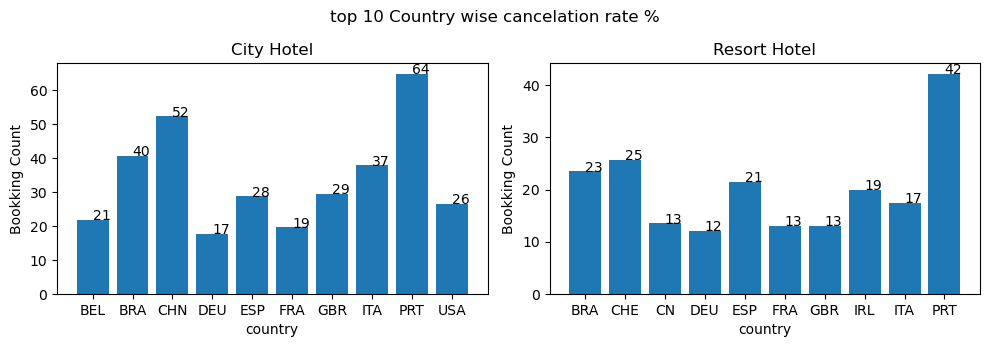

In [289]:
plt.figure(figsize=(10,6))
plt.subplot(2,2,1)
plt.bar(x,y)
plt.xlabel("country")
plt.ylabel("Bookking Count")
plt.title("City Hotel")
for i in range(len(x)):
    plt.text(x[i],y[i],int(y[i]))
plt.subplot(2,2,2)
plt.bar(r_x,r_y)
plt.xlabel("country")
plt.ylabel("Bookking Count")
plt.title("Resort Hotel")
for i in range(len(r_x)):
    plt.text(r_x[i],r_y[i],int(r_y[i]))
plt.suptitle("top 10 Country wise cancelation rate %")
plt.tight_layout()

In [13]:
#mostly  booking  according to lead time 

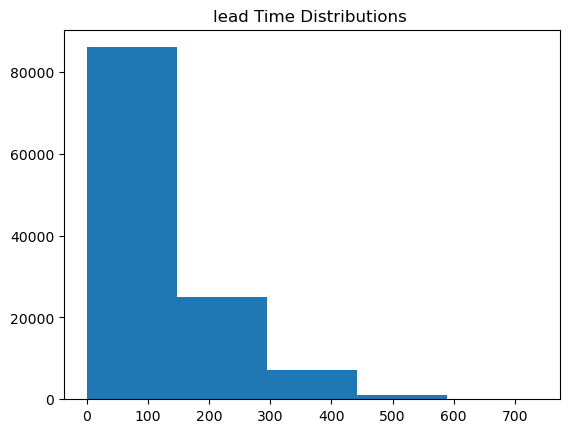

In [16]:
d=df["lead_time"]
plt.hist(d,bins=5)
plt.title("lead Time Distributions ")
plt.show()

In [17]:
#hotel Type Vs Lead Time


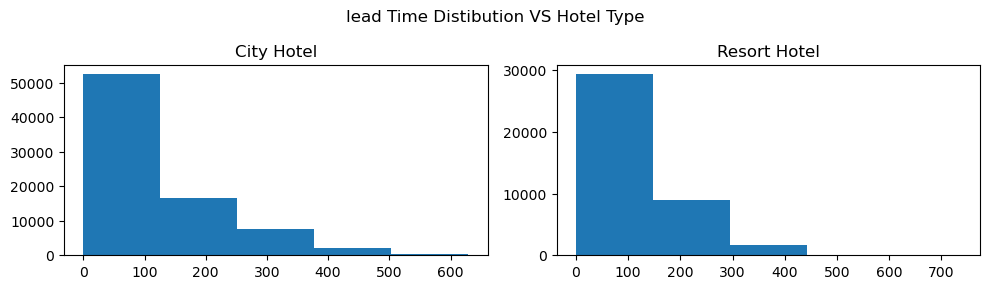

In [33]:
# City Hotel 
City_lead=df[df["hotel"]=="City Hotel"]
x=City_lead["lead_time"]
# Resort Hotel 
Resort_lead=df[df["hotel"]=="Resort Hotel"]
r_x=Resort_lead["lead_time"]

plt.figure(figsize=(10,5))
plt.subplot(2,2,1)
plt.hist(x,bins=5)
plt.title("City Hotel")
plt.subplot(2,2,2)
plt.hist(r_x,bins=5)
plt.title("Resort Hotel")
plt.suptitle("lead Time Distibution VS Hotel Type")
plt.tight_layout()

In [43]:
bins = [0, 30, 60, 90, 180, float('inf')]
labels = ['0-30', '31-60', '61-90', '91-180', '181+']

df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

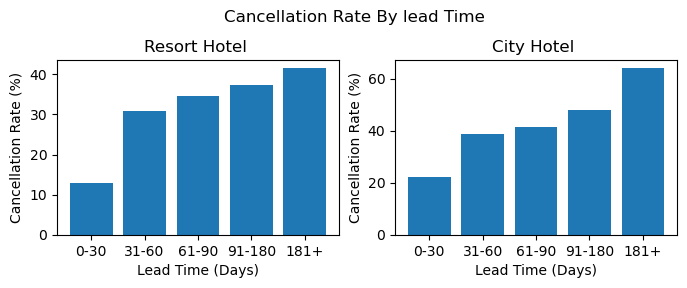

In [50]:
#Resort
resort = df[df['hotel'] == 'Resort Hotel']

resort_cancel = (
    resort.groupby('lead_time_group', observed=True)['is_canceled']
    .mean() * 100
)
#city

city = df[df['hotel'] == 'City Hotel']

city_cancel = (
    city.groupby('lead_time_group', observed=True)['is_canceled']
    .mean() * 100
)

#Resort Fig
plt.figure(figsize=(8,5))
plt.subplot(2,2,1)

plt.bar(resort_cancel.index, resort_cancel.values)

plt.xlabel("Lead Time (Days)")
plt.ylabel("Cancellation Rate (%)")
plt.title("Resort Hotel ")

#City Fig
plt.subplot(2,2,2)
plt.bar(city_cancel.index, city_cancel.values)

plt.xlabel("Lead Time (Days)")
plt.ylabel("Cancellation Rate (%)")
plt.title("City Hotel ")
plt.suptitle("Cancellation Rate By lead Time ")
plt.show()


In [36]:
df.groupby("country")["hotel"].value_counts()

country  hotel       
ABW      City Hotel        2
AGO      City Hotel      338
         Resort Hotel     24
AIA      City Hotel        1
ALB      City Hotel        9
                        ... 
ZAF      Resort Hotel     18
ZMB      City Hotel        1
         Resort Hotel      1
ZWE      City Hotel        2
         Resort Hotel      2
Name: count, Length: 291, dtype: int64